
# StockMate: Product Demand Forecasting

## Question 1: Machine Learning Approach

**Objective:** Predict how many units of a product will sell next week using past sales data.

**Dataset:** UCI Online Retail dataset.

**Approach:** Supervised Learning (Regression), because we are predicting a number.

**Algorithm:** Random Forest Regression, which uses multiple decision trees to make predictions.

**Inputs:** Sales from the previous three weeks, their average, and the month.

**Output:** Predicted weekly sales quantity.


In [1]:

import pandas as pd

# Load the Online Retail dataset
df = pd.read_excel("/Online Retail.xlsx")

# Display the first five transactions
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:

# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check the data types of each column
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (541909, 8)

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268


In [3]:

# Check cancelled invoices
cancelled = df["InvoiceNo"].astype(str).str.startswith("C").sum()

# Check negative or zero quantities
negative_qty = (df["Quantity"] < 0).sum()
zero_qty = (df["Quantity"] == 0).sum()

# Check invalid prices
invalid_prices = (df["UnitPrice"] <= 0).sum()

print("Cancelled invoices:", cancelled)
print("Negative quantities:", negative_qty)
print("Zero quantities:", zero_qty)
print("Zero or negative prices:", invalid_prices)


Cancelled invoices: 9288
Negative quantities: 10624
Zero quantities: 0
Zero or negative prices: 2517



## Question 2: Data Cleaning

The original dataset contained 541,909 rows.

We cleaned the data by:
- Removing duplicate records.
- Removing cancelled transactions.
- Removing negative or zero quantities and prices.
- Removing records with missing product descriptions.

We kept missing CustomerID values because they are not needed to predict product sales.

**Result:** 524,878 rows remained after cleaning.

**Purpose:** To prepare reliable sales records for our model.


In [4]:

# Create a copy to preserve the original dataset
df_clean = df.copy()

print("Original rows:", len(df_clean))

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove cancelled transactions
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only positive quantities
df_clean = df_clean[df_clean["Quantity"] > 0]

# Keep only positive prices
df_clean = df_clean[df_clean["UnitPrice"] > 0]

# Remove records without a product description
df_clean = df_clean.dropna(subset=["Description"])

# Display cleaning results
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

display(df_clean.head())


Original rows: 541909
Cleaned rows: 524878
Rows removed: 17031


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



## Question 2: Exploratory Data Analysis (EDA)

EDA helps us understand patterns in our sales data.

We made four observations:

1. **Products:** The dataset contains 3,922 different products.

2. **Popular Products:** Some products sell much more than others, meaning demand varies between products.

3. **Monthly Sales:** Sales were highest in November 2011, showing that sales change over time.

4. **Countries:** Most sales came from the United Kingdom, meaning the dataset mainly represents the UK market.

**Conclusion:** These findings help us understand sales patterns before training our model.


In [5]:

# Observation 1: Number of unique products
print("Unique products:", df_clean["StockCode"].nunique())

# Observation 2: Top 10 products by quantity sold
top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Best-Selling Products:")
print(top_products)

# Observation 3: Monthly sales quantities
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M")

monthly_sales = df_clean.groupby("Month")["Quantity"].sum()

print("\nMonthly Sales Quantities:")
print(monthly_sales)

# Observation 4: Top 10 countries by quantity sold
country_sales = (
    df_clean.groupby("Country")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Countries by Quantity Sold:")
print(country_sales)


Unique products: 3922

Top 10 Best-Selling Products:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

Monthly Sales Quantities:
Month
2010-12    358019
2011-01    387099
2011-02    282934
2011-03    376599
2011-04    307953
2011-05    395001
2011-06    388511
2011-07    399693
2011-08    421020
2011-09    569573
2011-10    621029
2011-11    751377
2011-12    313612
Freq: M, Name: Quantity, dtype: int64

Top 10 Countries by Quantity Sold:
Country
United Kingdom    4646906
Netherlands        200361
EIRE               147007
Germany            119154
France       


## Question 3: Model Development and Validation

**1. Data Preparation:** We grouped transactions into weekly sales for each product.

**2. Feature Engineering:** We used sales from the previous three weeks, their average and the month to predict weekly sales.

**3. Training and Testing:** We trained the model using earlier sales records (80% of weeks) and tested it on later records (20% of weeks).

**4. Model Training:** We trained Random Forest Regression using 100 decision trees. We limited tree depth to 12 and minimum samples per leaf to 5 to help prevent overfitting.

**5. Model Evaluation:** We measured prediction errors using MAE, RMSE and R².

**Testing Results:**
- MAE: 37.68 units
- RMSE: 116.09 units
- R²: 0.3837

**Conclusion:** Random Forest performed better than our simple last-week-sales baseline but prediction accuracy still needs improvement.


In [6]:

# Create a weekly sales dataset
weekly_sales = (
    df_clean.groupby([
        "StockCode",
        pd.Grouper(key="InvoiceDate", freq="W-SUN")
    ])["Quantity"]
    .sum()
    .reset_index()
)

# Rename columns for clarity
weekly_sales.columns = [
    "StockCode",
    "Week",
    "WeeklySales"
]

print("Weekly dataset shape:", weekly_sales.shape)

display(weekly_sales.head(10))


Weekly dataset shape: (101579, 3)


,StockCode,Week,WeeklySales
0,10002,2010-12-05,70
1,10002,2010-12-12,138
2,10002,2010-12-19,41
3,10002,2010-12-26,2
4,10002,2011-01-09,73
5,10002,2011-01-16,42
6,10002,2011-01-23,76
7,10002,2011-01-30,17
8,10002,2011-02-06,133
9,10002,2011-02-13,1


In [7]:

# Fill missing weeks between each product's first and last sale

weekly_complete = (
    weekly_sales
    .set_index("Week")
    .groupby("StockCode", group_keys=True)
    .apply(
        lambda group: group[["WeeklySales"]].reindex(
            pd.date_range(
                start=group.index.min(),
                end=group.index.max(),
                freq="W-SUN"
            ),
            fill_value=0
        ),
        include_groups=False
    )
    .reset_index()
)

# Rename the date column
weekly_complete.columns = [
    "StockCode", "Week", "WeeklySales"
]

# Display the results
print("Before filling:", weekly_sales.shape)
print("After filling:", weekly_complete.shape)

# Show the first 12 weeks for product 10002
display(
    weekly_complete[
        weekly_complete["StockCode"].astype(str) == "10002"
    ].head(12)
)


Before filling: (101579, 3)
After filling: (156664, 3)


,StockCode,Week,WeeklySales
0,10002,2010-12-05,70
1,10002,2010-12-12,138
2,10002,2010-12-19,41
3,10002,2010-12-26,2
4,10002,2011-01-02,0
5,10002,2011-01-09,73
6,10002,2011-01-16,42
7,10002,2011-01-23,76
8,10002,2011-01-30,17
9,10002,2011-02-06,133


In [8]:

# Step 8: Feature Engineering

# Sort the data by product and week
model_data = weekly_complete.sort_values(
    ["StockCode", "Week"]
).copy()

# Group sales by product
product_sales = model_data.groupby("StockCode")["WeeklySales"]

# Create historical sales features
model_data["Sales_Last_Week"] = product_sales.shift(1)

model_data["Sales_2_Weeks_Ago"] = product_sales.shift(2)

model_data["Sales_3_Weeks_Ago"] = product_sales.shift(3)

# Calculate average sales over the previous 3 weeks
model_data["Average_Last_3_Weeks"] = (
    model_data.groupby("StockCode")["WeeklySales"]
    .transform(
        lambda x: x.shift(1).rolling(3).mean()
    )
)

# Add calendar information
model_data["Month"] = model_data["Week"].dt.month

# Remove rows without enough sales history
model_data = model_data.dropna().copy()

# Display results
print("Model dataset shape:", model_data.shape)

display(model_data.head(10))


Model dataset shape: (145274, 8)


,StockCode,Week,WeeklySales,Sales_Last_Week,Sales_2_Weeks_Ago,Sales_3_Weeks_Ago,Average_Last_3_Weeks,Month
3,10002,2010-12-26,2,41.0,138.0,70.0,83.000000,12
4,10002,2011-01-02,0,2.0,41.0,138.0,60.333333,1
5,10002,2011-01-09,73,0.0,2.0,41.0,14.333333,1
6,10002,2011-01-16,42,73.0,0.0,2.0,25.000000,1
7,10002,2011-01-23,76,42.0,73.0,0.0,38.333333,1
8,10002,2011-01-30,17,76.0,42.0,73.0,63.666667,1
9,10002,2011-02-06,133,17.0,76.0,42.0,45.000000,2
10,10002,2011-02-13,1,133.0,17.0,76.0,75.333333,2
11,10002,2011-02-20,14,1.0,133.0,17.0,50.333333,2
12,10002,2011-02-27,36,14.0,1.0,133.0,49.333333,2


In [9]:

# Step 9: Split data into training and testing sets

# Select the features used for prediction
features = [
    "Sales_Last_Week",
    "Sales_2_Weeks_Ago",
    "Sales_3_Weeks_Ago",
    "Average_Last_3_Weeks",
    "Month"
]

# Set the target variable
target = "WeeklySales"

# Use earlier weeks for training (80%)
# and later weeks for testing (20%)
unique_weeks = sorted(model_data["Week"].unique())

split_index = int(len(unique_weeks) * 0.8)
split_date = unique_weeks[split_index]

# Split chronologically
train_data = model_data[
    model_data["Week"] < split_date
]

test_data = model_data[
    model_data["Week"] >= split_date
]

# Separate features and target
X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print("Split date:", split_date)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Training period:",
      train_data["Week"].min(),
      "to", train_data["Week"].max())

print("Testing period:",
      test_data["Week"].min(),
      "to", test_data["Week"].max())


Split date: 2011-10-02 00:00:00
Training records: 114258
Testing records: 31016
Training period: 2010-12-26 00:00:00 to 2011-09-25 00:00:00
Testing period: 2011-10-02 00:00:00 to 2011-12-11 00:00:00


In [10]:

# Step 10: Train Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

# Create our Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model using historical sales
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [11]:

# Step 11: Evaluate Random Forest Regression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Generate predictions
train_predictions = rf_model.predict(X_train)
test_predictions = rf_model.predict(X_test)

# Calculate evaluation metrics
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return mae, rmse, r2

# Evaluate training performance
train_mae, train_rmse, train_r2 = evaluate_model(
    y_train, train_predictions
)

# Evaluate testing performance
test_mae, test_rmse, test_r2 = evaluate_model(
    y_test, test_predictions
)

# Display results
print("TRAINING PERFORMANCE")
print("MAE:", round(train_mae, 2))
print("RMSE:", round(train_rmse, 2))
print("R2 Score:", round(train_r2, 4))

print("\nTESTING PERFORMANCE")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R2 Score:", round(test_r2, 4))


TRAINING PERFORMANCE
MAE: 21.41
RMSE: 66.75
R2 Score: 0.4889

TESTING PERFORMANCE
MAE: 37.68
RMSE: 116.09
R2 Score: 0.3837


In [12]:

# Step 12: Compare Random Forest with a baseline

# Baseline: predict the same sales as last week
baseline_predictions = X_test["Sales_Last_Week"]

# Evaluate baseline performance
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

# Display comparison
comparison = pd.DataFrame({
    "Model": ["Baseline (Last Week)", "Random Forest"],
    "MAE": [baseline_mae, test_mae],
    "RMSE": [baseline_rmse, test_rmse],
    "R2": [baseline_r2, test_r2]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))


MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2
0,Baseline (Last Week),39.9047,126.5895,0.2672
1,Random Forest,37.6807,116.0882,0.3837


In [13]:

# Step 13: Time-series cross-validation

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np

# Sort training records chronologically
cv_data = train_data.sort_values("Week").copy()

# Use unique weeks to avoid splitting the same week
# between training and validation
weeks = np.array(sorted(cv_data["Week"].unique()))

tscv = TimeSeriesSplit(n_splits=3)

cv_scores = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(weeks), start=1
):
    train_weeks = weeks[train_idx]
    val_weeks = weeks[val_idx]

    fold_train = cv_data[
        cv_data["Week"].isin(train_weeks)
    ]

    fold_val = cv_data[
        cv_data["Week"].isin(val_weeks)
    ]

    model = RandomForestRegressor(
        n_estimators=50,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        fold_train[features],
        fold_train[target]
    )

    predictions = model.predict(
        fold_val[features]
    )

    mae = mean_absolute_error(
        fold_val[target], predictions
    )

    cv_scores.append(mae)

    print(f"Fold {fold} MAE: {mae:.2f}")

print("\nAverage CV MAE:", round(np.mean(cv_scores), 2))


Fold 1 MAE: 21.87
Fold 2 MAE: 22.05
Fold 3 MAE: 26.73

Average CV MAE: 23.55


FEATURE IMPORTANCE


,Feature,Importance
3,Average_Last_3_Weeks,0.698507
0,Sales_Last_Week,0.105123
2,Sales_3_Weeks_Ago,0.076376
1,Sales_2_Weeks_Ago,0.070564
4,Month,0.049430


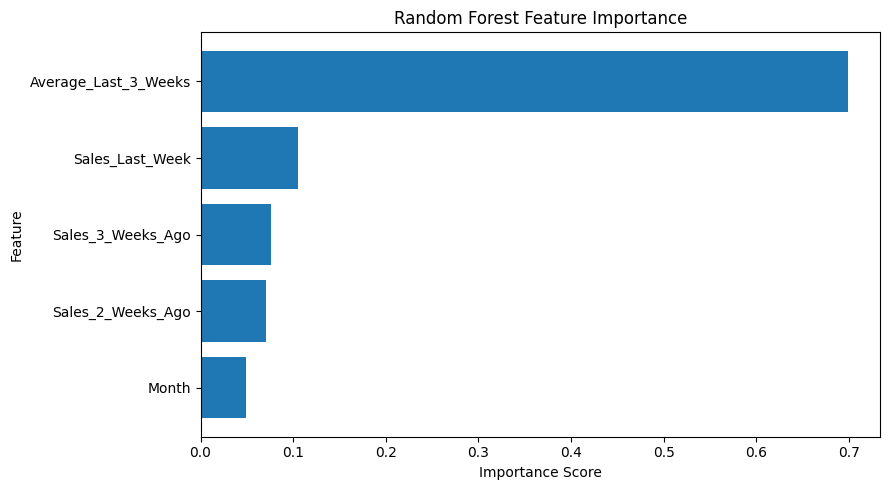

In [14]:

# Step 14: Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance scores
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE")
display(importance)

# Plot feature importance
plt.figure(figsize=(9, 5))
plt.barh(
    importance["Feature"],
    importance["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## Question 4: Further Model Validation

The following methods can be used to further validate our Random Forest model:

1. **Model Comparison:** Train other regression models, such as Linear Regression and Ridge Regression, using the same training and testing data. Compare their MAE, RMSE and R² scores.

2. **Time-Series Cross-Validation:** Test the model across different chronological periods to check whether its performance is consistent. We performed three-fold time-series cross-validation.

3. **Hyperparameter Tuning:** Experiment with different numbers of trees, maximum tree depths and minimum samples per leaf to identify better model settings.

These methods can help determine whether Random Forest is the most suitable model for StockMate's demand forecasting.